# Scenario risk quantification for "cut-in"

In [1]:
# Do the necessary imports
from copy import deepcopy
import os
import numpy as np
from domain_model import DocumentManagement, StateVariable
from simulation import SimulationCutIn, accaeb_cutin_pars, idm_cutin_pars, \
    IDMPlus, ACCAEB, KDE, kde_from_file
from case_study import get_kpi, case_study, CaseStudy, sample_reactiontime, reactiontime_density

In [2]:
# By default, do not overwrite previous results. Set to True to rerun all simulations.
OVERWRITE = True

## Several simulations

Below, two simulations are performed. One in which the ego vehicle is controlled by the ACC with AEB, and one in which the human (modelled using IDM+) is in control.

In [3]:
simulator_accaeb = SimulationCutIn(follower=ACCAEB(), follower_parameters=accaeb_cutin_pars,
                                min_simulation_time=5)
simulator_idmplus = SimulationCutIn(follower=IDMPlus(), follower_parameters=idm_cutin_pars,
                                   min_simulation_time=5)


array([1.90571103])

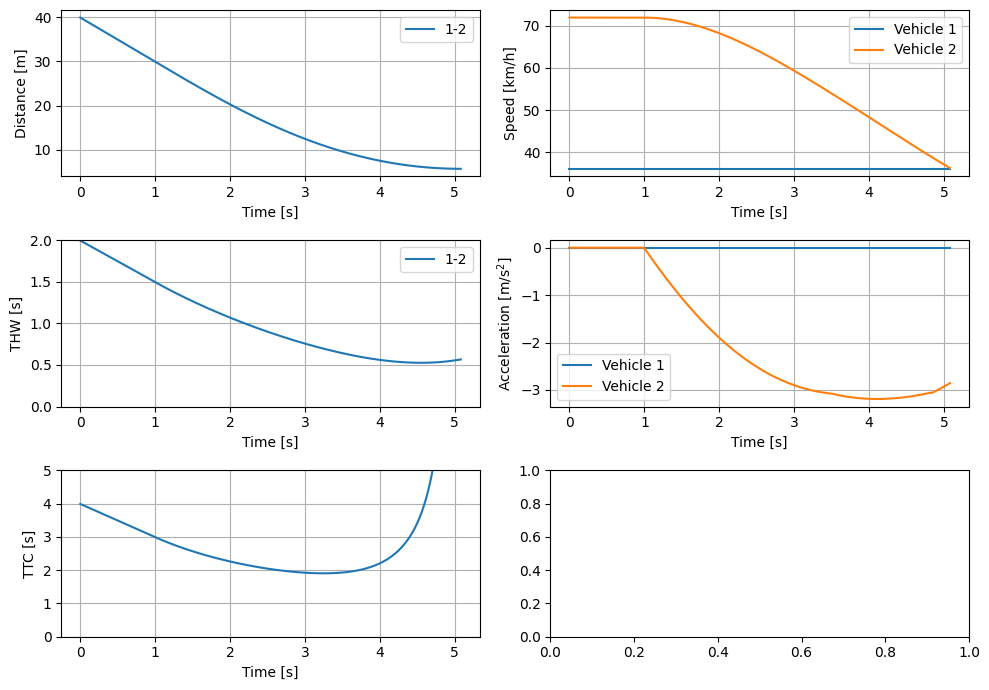

In [4]:
simulator_accaeb.simulation(dict(vlead=10, vego=20, dinit=40), plot=True)

array([2.99])

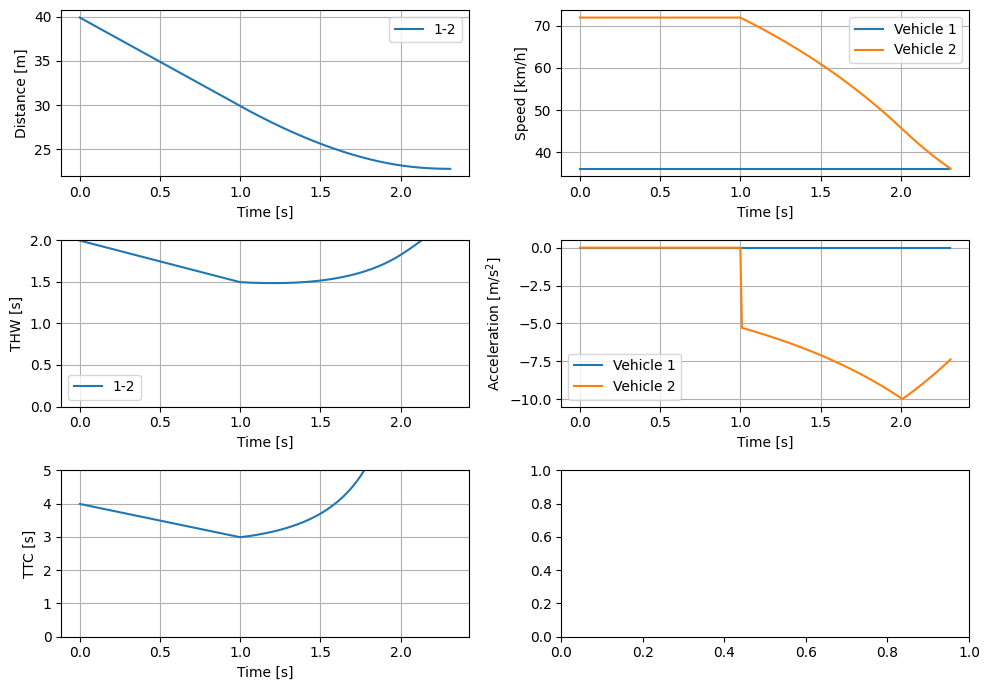

In [5]:
simulator_idmplus.simulation(dict(vlead=10, vego=20, dinit=40, reactiontime=1), plot=True)

## Create KDE of scenario parameters

In [6]:
# Load the data with the scenarios.
scenarios = DocumentManagement(os.path.join("data", "scenarios", "cut-in.json"))
print("Number of cut-in scenarios: {:d}"
      .format(len(scenarios.collections["scenario"])))

Number of cut-in scenarios: 297


In [7]:
filename = os.path.join("data", "kde", "cut-in.p")
if os.path.exists(filename) and not OVERWRITE:
    kde = kde_from_file(filename)
else:
    pars = []
    
    for key in scenarios.collections["scenario"]:
        scenario = scenarios.get_item("scenario", key)
        t_center = (scenario.get_tstart() + scenario.get_tend())/2
        vtarget, distance = scenario.get_state(scenario.get_actor_by_name("target vehicle"), 
                                               StateVariable.LON_TARGET, t_center)
        vego = scenario.get_state(scenario.get_actor_by_name("ego vehicle"), StateVariable.SPEED,
                                  t_center)
        pars.append([distance, vtarget, vego])

    kde = KDE(np.array(pars))
    kde.compute_bandwidth()
    kde.pickle(filename)

c:\GIT\ScenarioRiskQuantification\simulation\fastkde.py:495: RuntimeWarning: divide by zero encountered in log
  score = (np.sum(np.log(np.sum(np.exp(self.data_helpers.mindists


## Perform the case study

#### Some functions that are needed

In [8]:
# Function that checks if the scenario parameters are valid.
def check_pars(pars):
    if pars[0] <= 0 or pars[1] < 0 or pars[2] <= 0:  # dinit>0, vtarget>=0, vego>0
        return False
    if len(pars) > 3 and pars[3] <= 0:
        return False
    return True

# Function for sampling the parameters in case the ACCAEB model is used.
def func_sample_accaeb():
    return kde.sample()[0]

# Function for sampling the parameters in case the IDMPlus model is used.
def func_sample_idmplus():
    return np.concatenate((kde.sample()[0], [sample_reactiontime()]))

# Function for obtaining the pdf of the parameters in case the ACCAEB model is used.
def func_density_accaeb(pars):
    return kde.score_samples(pars)

# Function for obtaining the pdf of the parameters in case the IDMPlus model is used.
def func_density_idmplus(pars):
    return kde.score_samples(pars[:, :3]) * reactiontime_density(pars[:, 3])

#### With ACC & AEB, no triggering condition

In [9]:
default_parameters = dict(n=10000,
                          default_parameters=dict(amin=-10),
                          percentile=2,
                          func_validity_check=check_pars,
                          func_process_result=get_kpi)

In [10]:
pars_accaeb = dict(name="cut-in_accaeb",
                parameters=["dinit", "vlead", "vego"],
                simulator=simulator_accaeb,
                func_sample=func_sample_accaeb,
                func_density=func_density_accaeb)
pars_accaeb.update(default_parameters)
df_mc_accaeb, df_is_accaeb = case_study(CaseStudy(**pars_accaeb), overwrite=OVERWRITE)

100%|██████████| 10000/10000 [00:27<00:00, 364.61it/s]
c:\GIT\ScenarioRiskQuantification\simulation\fastkde.py:495: RuntimeWarning: divide by zero encountered in log
  score = (np.sum(np.log(np.sum(np.exp(self.data_helpers.mindists


Monte Carlo:
  Probability of collision: 1.00e-04 +/- 1.00e-04
  Probability of injury:    1.49e-07 +/- 1.49e-07


100%|██████████| 10000/10000 [00:22<00:00, 447.28it/s]

Importance sampling:
  Probability of collision: 2.41e-04 +/- 2.84e-05
  Probability of injury:    3.57e-07 +/- 4.16e-08


#### With IDM+, no triggering condition

In [11]:
pars_idmplus = dict(name="cut-in_idmplus",
                   parameters=["dinit", "vlead", "vego", "reactiontime"],
                   simulator=simulator_idmplus,
                   func_sample=func_sample_idmplus,
                   func_density=func_density_idmplus)
pars_idmplus.update(default_parameters)
df_mc_idmplus, df_is_idmplus = case_study(CaseStudy(**pars_idmplus), overwrite=OVERWRITE)

100%|██████████| 10000/10000 [00:56<00:00, 177.28it/s]
c:\GIT\ScenarioRiskQuantification\simulation\fastkde.py:495: RuntimeWarning: divide by zero encountered in log
  score = (np.sum(np.log(np.sum(np.exp(self.data_helpers.mindists


Monte Carlo:
  Probability of collision: 2.60e-03 +/- 5.09e-04
  Probability of injury:    4.81e-06 +/- 9.74e-07


100%|██████████| 10000/10000 [00:18<00:00, 526.73it/s]


Importance sampling:
  Probability of collision: 2.47e-03 +/- 1.82e-04
  Probability of injury:    4.64e-06 +/- 3.54e-07


#### With ACC & AEB, triggering condition: low $\mu$ and low visibility

In [12]:
AMIN = -3  # Corresponding to mu=0.3
MAX_VIEW = 60  # [m]

In [13]:
pars = deepcopy(pars_accaeb)
pars["default_parameters"].update(dict(amin=AMIN))
pars["default_parameters"].update(dict(max_view=MAX_VIEW))
pars["name"] = "lowmu_lowvisibility_cut_in_accaeb"
df_mc_accaeb_rain, df_is_accaeb_rain = case_study(CaseStudy(**pars), overwrite=OVERWRITE)

100%|██████████| 10000/10000 [00:28<00:00, 352.33it/s]
c:\GIT\ScenarioRiskQuantification\simulation\fastkde.py:495: RuntimeWarning: divide by zero encountered in log
  score = (np.sum(np.log(np.sum(np.exp(self.data_helpers.mindists


Monte Carlo:
  Probability of collision: 1.90e-03 +/- 4.35e-04
  Probability of injury:    3.91e-06 +/- 9.34e-07


100%|██████████| 10000/10000 [00:25<00:00, 396.40it/s]


Importance sampling:
  Probability of collision: 1.95e-03 +/- 1.00e-04
  Probability of injury:    4.22e-06 +/- 2.37e-07


#### With IDM+, triggering condition: low $\mu$ and low visibility

In [14]:
pars = deepcopy(pars_idmplus)
pars["default_parameters"].update(dict(amin=AMIN))
pars["default_parameters"].update(dict(max_view=MAX_VIEW))
pars["name"] = "lowmu_lowvisibility_cut_in_idmplus"
df_mc_idmplus_rain, df_is_idmplus_rain = case_study(CaseStudy(**pars), overwrite=OVERWRITE)

100%|██████████| 10000/10000 [00:57<00:00, 173.79it/s]
c:\GIT\ScenarioRiskQuantification\simulation\fastkde.py:495: RuntimeWarning: divide by zero encountered in log
  score = (np.sum(np.log(np.sum(np.exp(self.data_helpers.mindists


Monte Carlo:
  Probability of collision: 3.50e-03 +/- 5.91e-04
  Probability of injury:    6.75e-06 +/- 1.20e-06


100%|██████████| 10000/10000 [00:26<00:00, 371.19it/s]


Importance sampling:
  Probability of collision: 3.49e-03 +/- 1.76e-04
  Probability of injury:    6.75e-06 +/- 3.76e-07


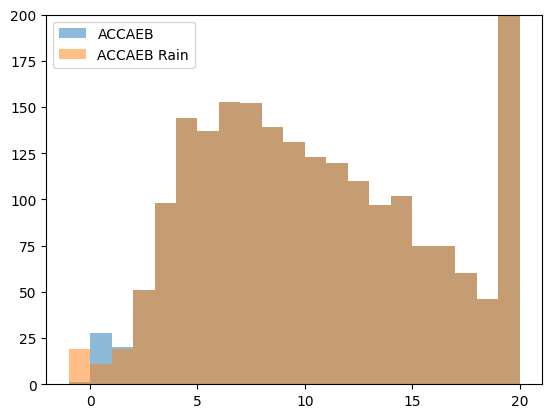

In [22]:
import numpy as np
import matplotlib.pyplot as plt

bins = np.arange(-1, 21, 1)
fig, ax = plt.subplots()

ax.hist(df_mc_accaeb.result.clip(-1, 20), bins=bins, alpha=0.5, label="ACCAEB")
ax.hist(df_mc_accaeb_rain.result.clip(-1, 20), bins=bins, alpha=0.5, label="ACCAEB Rain")
plt.ylim(0, 200)
ax.legend()
plt.show()

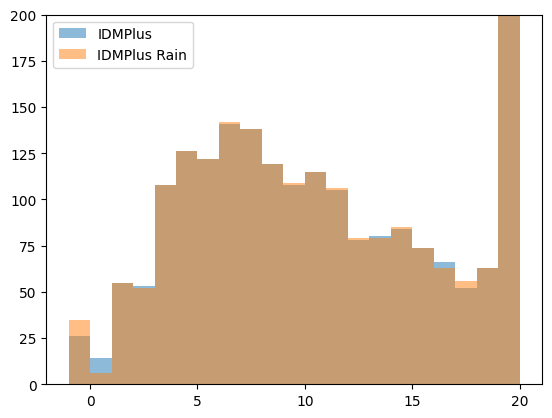

In [23]:
fig, ax = plt.subplots()

ax.hist(df_mc_idmplus.result.clip(-1, 20), bins=bins, alpha=0.5, label="IDMPlus")
ax.hist(df_mc_idmplus_rain.result.clip(-1, 20), bins=bins, alpha=0.5, label="IDMPlus Rain")
plt.ylim(0, 200)
ax.legend()
plt.show()